# Assessment 2 — Retail Dynamics Weekly Sail forecasting

imports shared libraries/modules

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import plot_tree
from sklearn.inspection import permutation_importance


warnings.filterwarnings("ignore")

load the df

In [2]:
df = pd.read_csv('retail_dynamics_weekly_sales.csv')

## Task 1

### Structure Analysis

<p>get general overview of the dataset's structure</p>

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   StoreID  1500 non-null   str    
 1   Week     1500 non-null   int64  
 2   Price    1500 non-null   float64
 3   Display  1500 non-null   str    
 4   Media    1500 non-null   int64  
 5   Sales    1500 non-null   int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 80.5 KB


<p>inspect the first 5 rows for each variable to glean how data is represented in the dataset</p>

In [4]:
df.head(5)

,StoreID,Week,Price,Display,Media,Sales
0,S1115,2,8.74,No,0,295
1,S1076,2,9.31,N,0,234
2,S1102,3,10.53,no,0,237
3,S1057,8,13.45,No,1,225
4,S1102,6,9.01,no,0,233


<p>quick summary of dataset size i.e. row/column count</p>

In [5]:
df.shape

(1500, 6)

### Content Analysis

display frequency

In [6]:
display_freq = ["Display"]

for row in display_freq:
    print(df[display_freq].value_counts(dropna=False))

Display
No         364
N          337
no         333
Y          166
yes        155
Yes        145
Name: count, dtype: int64


check for unique identifiers

In [7]:
print("Unique StoreIDs:", df["StoreID"].nunique())
print("Duplicate StoreIDs:", df["StoreID"].duplicated().sum())
print(df["StoreID"].nunique() == len(df))

Unique StoreIDs: 150
Duplicate StoreIDs: 1350
False


<p>check for duplicate records in dataset</p>

In [8]:
df.duplicated().sum()

np.int64(0)

### Invalid Data Analysis

<p>check for invalid strings in categorical columns</p>

In [9]:
invalid_str = df[['Display', 'StoreID']].isin(["?", ""])
print(invalid_str.sum())

Display    0
StoreID    0
dtype: int64


check for nulls

In [10]:
df.isnull().sum()

StoreID    0
Week       0
Price      0
Display    0
Media      0
Sales      0
dtype: int64

### Descriptive Statistics

Statistical Summary for numerical columns

In [11]:
df.describe(include='number').round(2)

,Week,Price,Media,Sales
count,1500.00,1500.00,1500.00,1500.00
mean,5.50,11.98,0.25,235.65
std,2.87,2.16,0.43,42.90
min,1.00,6.50,0.00,120.00
25%,3.00,10.52,0.00,206.00
50%,5.50,11.97,0.00,234.00
75%,8.00,13.48,1.00,264.00
max,10.00,17.25,1.00,360.00


Examine sales specifically

In [12]:
df['Sales'].describe().round(2)

count    1500.00
mean      235.65
std        42.90
min       120.00
25%       206.00
50%       234.00
75%       264.00
max       360.00
Name: Sales, dtype: float64

### Sales behaviour analysis

Distribution of Sales

<Axes: >

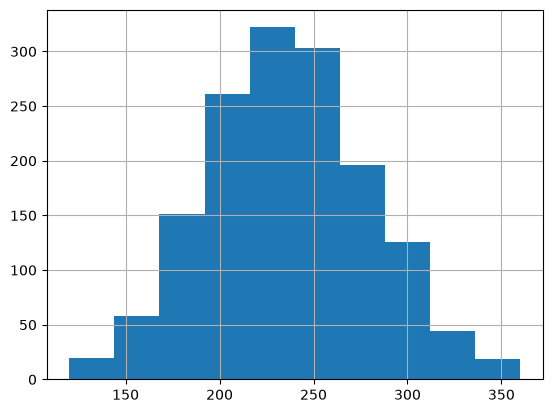

In [13]:
df['Sales'].hist()

sales by store

In [14]:
Store_sales = df.groupby('StoreID')['Sales'].mean()

Store_sales.describe().round(2)

count    150.00
mean     235.65
std       21.68
min      179.50
25%      220.42
50%      234.75
75%      250.42
max      285.50
Name: Sales, dtype: float64

Calculate stores with top 5 lowest vs highest sales

In [15]:
print("Lowest average sales:")
print(Store_sales.nsmallest(5))

print("\nHighest average sales:")
print(Store_sales.nlargest(5))

Lowest average sales:
StoreID
S1120    179.5
S1100    186.8
S1085    190.7
S1031    199.4
S1103    199.8
Name: Sales, dtype: float64

Highest average sales:
StoreID
S1080    285.5
S1063    285.0
S1105    284.6
S1130    281.1
S1137    279.2
Name: Sales, dtype: float64


Sales under Display vs No display

In [16]:
df.groupby('Display')['Sales'].mean().round(2)

Display
N      224.93
No     221.64
Y      259.40
Yes    263.12
no     224.76
yes    264.16
Name: Sales, dtype: float64

Sales under Media vs No Media

In [17]:
media_sales = df.groupby('Media')['Sales'].mean().round(2)

print("No Media:", media_sales[0])
print("Media:", media_sales[1])

No Media: 228.37
Media: 257.19


Sales under Higher price vs lower price

find median price to establish higher/lower boundary cutoff

In [18]:
price_median = df['Price'].median()

print("Median Price:", price_median)

Median Price: 11.97


create a temporary price level category

In [19]:
df['Price_Level'] = np.where(
    df['Price'] >= price_median,
    'Higher Price',
    'Lower Price'
)

check that worked

In [20]:
df['Price_Level'].value_counts()

Price_Level
Higher Price    751
Lower Price     749
Name: count, dtype: int64

avg sales at higher vs lower price level

In [21]:
price_sales = df.groupby('Price_Level')['Sales'].mean().round(2)
price_sales

Price_Level
Higher Price    220.62
Lower Price     250.73
Name: Sales, dtype: float64

In [22]:
df['Display'].value_counts()

Display
No     364
N      337
no     333
Y      166
yes    155
Yes    145
Name: count, dtype: int64

Sales Comparison

In [23]:
display = df['Display'].astype('string').str.strip().str.casefold()

display_yes = df.loc[display.isin(['yes', 'y']), 'Sales'].mean()
display_no = df.loc[display.isin(['no', 'n']), 'Sales'].mean()

comparison = pd.DataFrame({
    'Condition': [
        'Display',
        'No Display',
        'Media',
        'No Media',
        'Higher Price',
        'Lower Price'
    ],
    'Average Sales': [
        display_yes,
        display_no,
        media_sales[1],
        media_sales[0],
        price_sales['Higher Price'],
        price_sales['Lower Price']
    ]
})

comparison

,Condition,Average Sales
0,Display,262.141631
1,No Display,223.715667
2,Media,257.190000
3,No Media,228.370000
4,Higher Price,220.620000
5,Lower Price,250.730000


<Axes: title={'center': 'Average Weekly Sales by Promotional Condition'}, xlabel='Condition', ylabel='Average Sales (units)'>

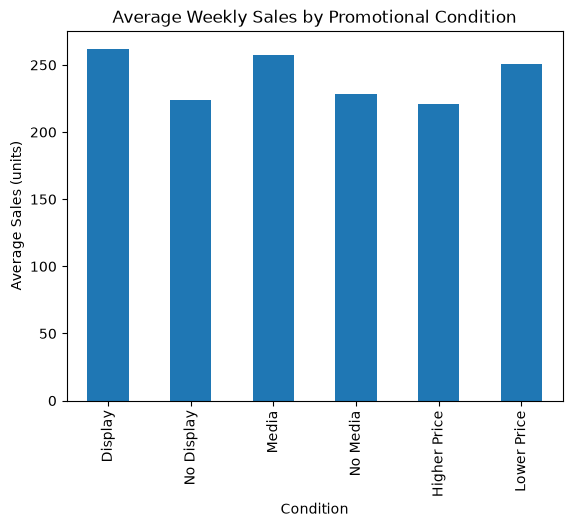

In [24]:
comparison.plot(
    x='Condition',
    y='Average Sales',
    kind='bar',
    legend=False,
    title='Average Weekly Sales by Promotional Condition',
    ylabel='Average Sales (units)'
)

## Task 2

### Data Cleansing

standardise different values as per frequency analysis

In [25]:
df['Display'] = df['Display'].str.strip().str.lower()

Binary encode Display such that No = 0 and Yes = 1

In [26]:
df['Display'] = df['Display'].replace({
    'no': 0,
    'n': 0,
    'yes': 1,
    'y': 1
})

Check encoding

In [27]:
df['Display'].value_counts(dropna=False)

Display
0    1034
1     466
Name: count, dtype: int64

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   StoreID      1500 non-null   str    
 1   Week         1500 non-null   int64  
 2   Price        1500 non-null   float64
 3   Display      1500 non-null   object 
 4   Media        1500 non-null   int64  
 5   Sales        1500 non-null   int64  
 6   Price_Level  1500 non-null   str    
dtypes: float64(1), int64(3), object(1), str(2)
memory usage: 106.3+ KB


### Prepare the modelling data

Create a time-based train/test split

In [66]:
features = ["Week", "Price", "Display", "Media"]
target = "Sales"

train = df.loc[df["Week"] <= 8].copy()
test = df.loc[df["Week"].isin([9, 10])].copy()

X_train = train[features]
y_train = train[target]
X_test = test[features]
y_test = test[target]

create table summarising test/train split observation count + as a % of dataset

In [67]:
split_summary = pd.DataFrame([
    {
        "Dataset": "Training",
        "Weeks": f'{train["Week"].min()}–{train["Week"].max()}',
        "Observations": len(train),
        "% of Dataset": round(len(train) / (len(train) + len(test)) * 100, 1)
    },
    {
        "Dataset": "Test",
        "Weeks": f'{test["Week"].min()}–{test["Week"].max()}',
        "Observations": len(test),
        "% of Dataset": round(len(test) / (len(train) + len(test)) * 100, 1)
    },
    {
        "Dataset": "Total",
        "Weeks": f'{min(train["Week"].min(), test["Week"].min())}–{max(train["Week"].max(), test["Week"].max())}',
        "Observations": len(train) + len(test),
        "% of Dataset": 100.0
    }
])

split_summary

,Dataset,Weeks,Observations,% of Dataset
0,Training,1–8,1200,80.0
1,Test,9–10,300,20.0
2,Total,1–10,1500,100.0


create 5 time-ordered validation folds for tuning the models

In [30]:
training_weeks = sorted(train["Week"].unique())
cv_splits = [
    (
        np.flatnonzero(X_train["Week"].to_numpy() < week),
        np.flatnonzero(X_train["Week"].to_numpy() == week)
    )
    for week in training_weeks[3:]
]

print("No. of validation folds:", len(cv_splits))
print("training/validation rows in 1st fold:",
      (len(cv_splits[0][0]), len(cv_splits[0][1])))

No. of validation folds: 5
training/validation rows in 1st fold: (450, 150)


## Task 3

### evaluation metrics

create function to pendalise underforecasting + function that caculates model performance based on MAE, RMSE, r2, etc

In [31]:

def asymmetric_cost(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    underforecast = y_pred < y_true
    absolute_error = np.abs(y_true - y_pred)

    return np.mean(
        np.where(underforecast, 2 * absolute_error, absolute_error)
    )


def evaluate_predictions(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
        "Underforecast rate (%)": 100 * np.mean(
            np.asarray(y_pred) < np.asarray(y_true)
        ),
        "Asymmetric cost": asymmetric_cost(y_true, y_pred)
    }


# Store predictions for comparing all models
predictions = {}


### Baseline Model

create baseline (weekly avg sales) using training data

In [32]:
train_df = df[df["Week"].between(1, 8)].copy()
test_df = df[df["Week"].between(9, 10)].copy()

store_avg_sales = train_df.groupby("StoreID")["Sales"].mean()

baseline_predictions = test_df["StoreID"].map(store_avg_sales)

predictions["Baseline"] = baseline_predictions.to_numpy()


evaluate/display baseline testing accuracy

In [33]:
baseline_results = evaluate_predictions(
    "Baseline",
    y_test,
    predictions["Baseline"]
)

print(pd.DataFrame([baseline_results]).round(3).to_string(index=False))

   Model    MAE   RMSE    R2  Underforecast rate (%)  Asymmetric cost
Baseline 31.942 40.593 0.056                  47.333            47.32


### Fit OLS regression

fit the OLS model + display coefficients

In [34]:
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

predictions["OLS"] = ols_model.predict(X_test)

ols_coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": ols_model.coef_
})

ols_coefficients.loc[len(ols_coefficients)] = ["Intercept", ols_model.intercept_]
ols_coefficients.round(3)


,Feature,Coefficient
0,Week,-0.660
1,Price,-9.227
2,Display,39.951
3,Media,27.985
4,Intercept,330.058


Display test performance results in table

In [35]:
print("OLS test performance:")
print(pd.DataFrame([
    evaluate_predictions("OLS", y_test, predictions["OLS"])
]).round(3))

OLS test performance:
  Model     MAE    RMSE     R2  Underforecast rate (%)  Asymmetric cost
0   OLS  25.449  31.144  0.444                  49.667           38.984


### Tune Ridge regression

In [36]:
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error",
    cv=cv_splits
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
predictions["Ridge"] = ridge_model.predict(X_test)


Display test performance results

In [37]:
print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print(pd.DataFrame([
    evaluate_predictions("Ridge", y_test, predictions["Ridge"])
]).round(3))

Best Ridge alpha: 0.01
   Model     MAE    RMSE     R2  Underforecast rate (%)  Asymmetric cost
0  Ridge  25.449  31.144  0.444                  49.667           38.984


investigate if test performance of ridge/ols is identical or just highly similar (due to ridge penalty)

In [38]:
print(
    "Results exactly identical (T/F):",
    np.array_equal(predictions["OLS"], predictions["Ridge"])
)

Results exactly identical (T/F): False


### Tune Random Forest

In [39]:
forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=42))
])

forest_search = GridSearchCV(
    forest_pipeline,
    param_grid={
        "model__n_estimators": [100, 300],
        "model__max_depth": [3, 5, None],
        "model__min_samples_leaf": [5, 10]
    },
    scoring="neg_mean_absolute_error",
    cv=cv_splits
)
forest_search.fit(X_train, y_train)
forest_model = forest_search.best_estimator_
predictions["Random Forest"] = forest_model.predict(X_test)

show best hyperparamaters found by above

In [40]:
best_forest_params = pd.DataFrame(
    forest_search.best_params_.items(),
    columns=["Hyperparameter", "Best Value"]
)

print(best_forest_params.to_string(index=False))

         Hyperparameter  Best Value
       model__max_depth           5
model__min_samples_leaf           5
    model__n_estimators         300


Display test performance results

In [41]:
print("Random Forest test performance:")
print(pd.DataFrame([
    evaluate_predictions("Random Forest", y_test, predictions["Random Forest"])
]).round(3))


Random Forest test performance:
           Model     MAE    RMSE     R2  Underforecast rate (%)  \
0  Random Forest  25.862  31.508  0.431                    48.0   

   Asymmetric cost  
0           38.787  


 Rank Forest feature importance

In [42]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": forest_model.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

feature_importance.round(3)

,Feature,Importance
1,Price,0.510
2,Display,0.319
3,Media,0.138
0,Week,0.033


### tune Lasso

In [74]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error",
    cv=cv_splits
)

lasso_search.fit(X_train, y_train)

lasso_model = lasso_search.best_estimator_
predictions["Lasso"] = lasso_model.predict(X_test)

display results of tuning

In [77]:
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("Best cross-validation MAE:", round(-lasso_search.best_score_, 3))

Best Lasso alpha: 0.1
Best cross-validation MAE: 24.594


### Compare all models on validaton folds

In [84]:
from sklearn.base import clone

validation_models = {
    "OLS": ols_model,
    "Ridge": ridge_search.best_estimator_,
    "Random Forest": forest_search.best_estimator_,
    "Lasso": lasso_model
}

validation_results = []

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    for name, model in validation_models.items():
        model_fold = clone(model)
        model_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

        val_predictions = model_fold.predict(X_train.iloc[val_idx])

        result = evaluate_predictions(
            name,
            y_train.iloc[val_idx],
            val_predictions
        )
        result["Fold"] = fold
        validation_results.append(result)

validation_df = pd.DataFrame(validation_results)

validation_summary = (
    validation_df.groupby("Model")
    [["MAE", "RMSE", "R2", "Underforecast rate (%)", "Asymmetric cost"]]
    .mean()
    .sort_values("Asymmetric cost")
)

validation_summary.round(3)

,MAE,RMSE,R2,Underforecast rate (%),Asymmetric cost
Model,,,,,
Lasso,24.594,30.886,0.460,52.133,36.430
OLS,24.598,30.896,0.460,52.133,36.442
Ridge,24.598,30.896,0.460,52.133,36.442
Random Forest,25.112,31.847,0.426,50.267,37.149


### Compare all models on the same test rows

In [85]:
results = pd.DataFrame([
    evaluate_predictions(name, y_test, pred)
    for name, pred in predictions.items()
])

baseline_cost = results.loc[results["Model"] == "Baseline", "Asymmetric cost"].iloc[0]
results["Asymmetric cost improvement vs baseline (%)"] = (
    (baseline_cost - results["Asymmetric cost"]) / baseline_cost * 100
)
results.sort_values("Asymmetric cost").reset_index(drop=True).round(5)

,Model,MAE,RMSE,R2,Underforecast rate (%),Asymmetric cost,Asymmetric cost improvement vs baseline (%)
0,Random Forest,25.86152,31.50792,0.43098,48.00000,38.78671,18.03316
1,Lasso,25.44978,31.12434,0.44475,49.66667,38.88961,17.81570
2,OLS,25.44871,31.14426,0.44404,49.66667,38.98393,17.61637
3,Ridge,25.44871,31.14424,0.44404,49.66667,38.98394,17.61636
4,Baseline,31.94250,40.59264,0.05554,47.33333,47.32000,0.00000


### Predictions vs Actual output

produce table showing predicted vs actual output, sorted by week  and including predictions errors

In [86]:
prediction_vs_actual = test[["Week", "Sales"]].copy()
prediction_vs_actual = prediction_vs_actual.rename(
    columns={"Sales": "Actual Sales"}
)

for feature, prediction in predictions.items():
    prediction_vs_actual[feature] = np.asarray(prediction)

for feature in predictions.keys():
    prediction_vs_actual[feature + " error"] = (
        prediction_vs_actual[feature]
        - prediction_vs_actual["Actual Sales"]
    )

prediction_vs_actual = prediction_vs_actual.sort_values(
    "Week", ascending=False
).reset_index(drop=True)

prediction_vs_actual.head(10).round(2)

,Week,Actual Sales,Baseline,OLS,Ridge,Random Forest,Lasso,Baseline error,OLS error,Ridge error,Random Forest error,Lasso error
0,10,237,244.25,238.11,238.11,237.64,238.31,7.25,1.11,1.11,0.64,1.31
1,10,232,262.12,200.37,200.37,203.84,200.77,30.12,-31.63,-31.63,-28.16,-31.23
2,10,226,265.25,222.70,222.70,224.73,222.99,39.25,-3.30,-3.30,-1.27,-3.01
3,10,196,231.25,238.57,238.57,238.31,238.77,35.25,42.57,42.57,42.31,42.77
4,10,272,227.62,277.35,277.35,268.05,277.27,-44.38,5.35,5.35,-3.95,5.27
5,10,236,220.25,247.52,247.52,248.38,247.66,-15.75,11.52,11.52,12.38,11.66
6,10,197,216.62,209.23,209.23,209.22,209.59,19.62,12.23,12.23,12.22,12.59
7,10,230,226.62,238.14,238.14,243.26,238.28,-3.38,8.14,8.14,13.26,8.28
8,10,156,250.75,208.52,208.52,199.97,208.82,94.75,52.52,52.52,43.97,52.82
9,10,197,235.88,221.13,221.13,224.53,221.43,38.88,24.13,24.13,27.53,24.43


### Visualise predictions vs actual sales for best model (RF) 

visualise actual vs predicted results for the best model (based on assymetric cost/business constraints)

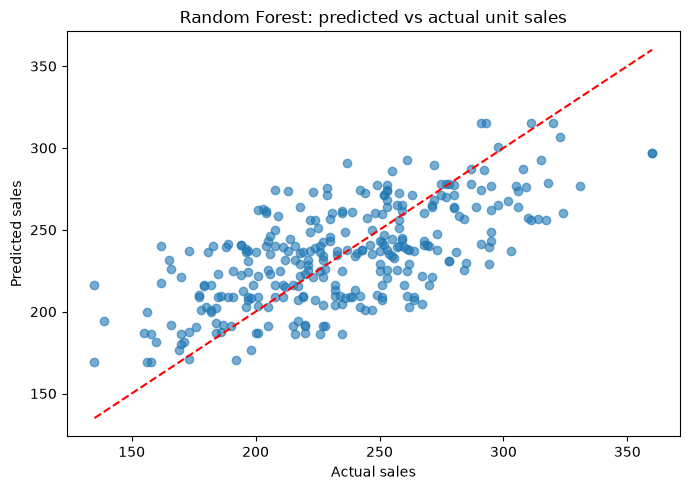

In [87]:
best_model = results.sort_values("Asymmetric cost").iloc[0]["Model"]
best_predictions = predictions[best_model]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.6)
limits = [min(y_test.min(), best_predictions.min()),
          max(y_test.max(), best_predictions.max())]
plt.plot(limits, limits, "r--")
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.title(f"{best_model}: predicted vs actual unit sales")
plt.tight_layout()
plt.show()

compare best model's MAE over the baseline

In [88]:

baseline_row = results.loc[results["Model"] == "Baseline"].iloc[0]

best_row = results.loc[results["Model"] == best_model].iloc[0]

baseline_mae = baseline_row["MAE"]
selected_mae = best_row["MAE"]

mae_improvement_pct = (
    (baseline_mae - selected_mae) / baseline_mae * 100
)

error_reduction = baseline_mae - selected_mae

projected_units_per_forecast = max(0, error_reduction)
projected_total_units = projected_units_per_forecast * len(y_test)

print(f"Best model by asymmetric cost: {best_model}")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Selected model MAE: {selected_mae:.2f}")
print(f"MAE improvement vs baseline: {mae_improvement_pct:.1f}%")
print(f"Absolute MAE reduction: {baseline_mae - selected_mae:.2f} units/week")
print(f"Possible inventory savings across {len(y_test)} forecasts: {projected_total_units:.0f} units")


Best model by asymmetric cost: Random Forest
Baseline MAE: 31.94
Selected model MAE: 25.86
MAE improvement vs baseline: 19.0%
Absolute MAE reduction: 6.08 units/week
Possible inventory savings across 300 forecasts: 1824 units


### Feature Importance

Rank features based on how much they affect the MAE of test set

In [89]:
feature_importance = permutation_importance(
    forest_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42
)

feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance (MAE increase)": feature_importance.importances_mean,
    "Importance Standard Dev": feature_importance.importances_std
}).sort_values(
    "Importance (MAE increase)",
    ascending=False
).reset_index(drop=True)

print(feature_importance_df.round(4))


   Feature  Importance (MAE increase)  Importance Standard Dev
0  Display                     7.9542                   1.0330
1    Price                     7.0014                   0.7039
2    Media                     2.8951                   0.6240
3     Week                     0.0000                   0.0000
